In [102]:
import numpy as np
import matplotlib.pyplot as plt

In [103]:
def solve_bvp_ghost(eps, p, q, r, a, b, alpha0, beta0, gamma0, alpha1, beta1, gamma1, N):
  """
  Solves the BVP eps y''+P(X)y'+Q(x)y = r(x) using finite differences with fictious points.
  """
  h = (b-a)/N
  x = np.linspace(a, b, N+1)
  A = np.zeros((N+1, N+1))
  B = np.zeros(N+1)
  x0 = x[0]
  xN = x[-1]
  # Interior Points using central differences for y'' and y'
  for i in range(1, N):
    xi = x[i]
    A[i, i-1] = eps - p(xi)*h/2     # Left Neighbor
    A[i, i] = q(xi)*h**2 - 2*eps    # Center
    A[i, i+1] = eps + p(xi)*h/2     # Right Neighbor
    B[i] = r(xi) * h**2
  # Ghost point formulation for boundary conditions
  A[0, 0] = h*alpha0*(2*eps-h*p(a)) + beta0*(q(a)*h**2-2*eps)
  A[0, 1] = 2 * eps * beta0
  B[0] = h*(2*eps-h*p(a))*gamma0 + h**2*r(a)*beta0
  A[N, N-1] = -2 * eps * beta1
  A[N, N] = h*alpha1*(2*eps+h*p(b)) - beta1*(q(b)*h**2-2*eps)
  B[N] = gamma1*h*(2*eps+h*p(b)) - h**2*beta1*r(b)
  # Solve the system
  Y = np.linalg.solve(A, B)
  # print(A, B)
  return x, Y

In [104]:
# Example: y''+2y'-3y = 9x, 0 <= x <= 1, with y(0) = 1, y'(1) = 2
def p(x):
  return x

In [105]:
def q(x):
  return -3

In [106]:
def r(x):
  return 9 * np.exp(x)

In [107]:
eps = 1
a,b = 0, 1
alpha0, beta0, gamma0 = 1, 0, 1    # y(0) = 1
alpha1, beta1, gamma1 = 0, 1, 2    # y(1) = 2
N = 20

In [108]:
x, Y = solve_bvp_ghost(eps, p, q, r, a, b, alpha0, beta0, gamma0, alpha1, beta1, gamma1, N)

In [109]:
# Exact solution for error analysis (if known, here assumed as an approximation for demonstration)
def exact_solution(x):
  return ((3*np.exp(1)-5) * np.exp(-3*x) + (5+9*np.exp(-3)) * np.exp(x)) / (np.exp(1) + 3*np.exp(-3)) - 3*x - 2

In [110]:
exact_vals = np.array([exact_solution(xi) for xi in x])
errors = np.abs(Y - exact_vals)

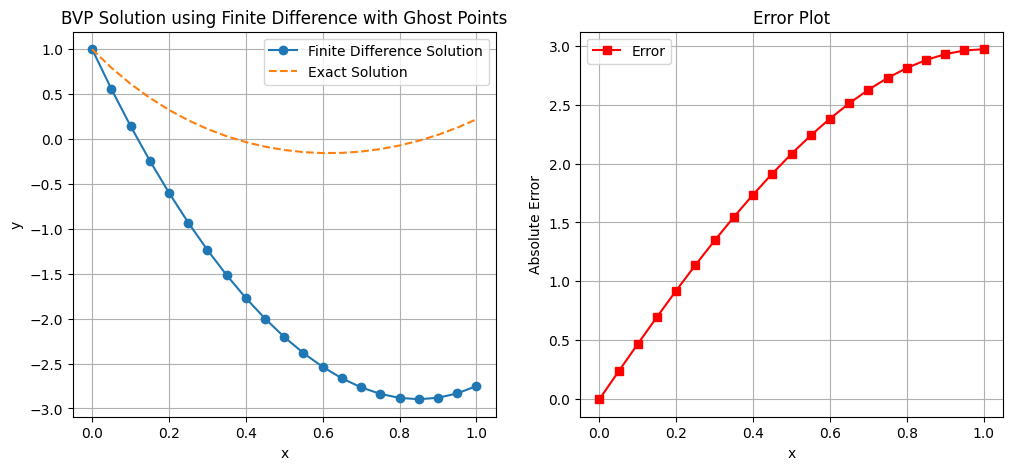

In [111]:
# Plot the results
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(x, Y, label='Finite Difference Solution', marker='o')
plt.plot(x, exact_vals, '--', label='Exact Solution')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.title('BVP Solution using Finite Difference with Ghost Points')
plt.grid()
# Error Plot
plt.subplot(1, 2, 2)
plt.plot(x, errors, label='Error', marker='s', color='r')
plt.xlabel('x')
plt.ylabel('Absolute Error')
plt.legend()
plt.title('Error Plot')
plt.grid()
plt.show()